In [2]:
# Cell 1: imports and settings
import random
import torch
import matplotlib.pyplot as plt
from captcha.image import ImageCaptcha
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

CHARSET = "23456789ABCDEFGHJKLMNPQRSTUVWXYZ"
LENGTH = 5

In [3]:
# Cell 2: helper functions
def random_text():
    return "".join(random.choice(CHARSET) for _ in range(LENGTH))

def encode(text):
    return torch.tensor([CHARSET.index(c) for c in text], dtype=torch.long)

def decode(tensor):
    return "".join(CHARSET[int(n)] for n in tensor)

for _ in range(1000):
    t = random_text()
    if decode(encode(t)) != t:
        print(t)

In [4]:
# Cell 3: Dataset
class CaptchaDataset(Dataset):
    def __init__(self, size):
        self.size = size
        self.generator = ImageCaptcha(width=160, height=60)
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return self.size

    def __getitem__(self, idx):
        text = random_text()
        img = self.generator.generate_image(text).convert("L")
        return self.to_tensor(img), encode(text)

torch.Size([64, 1, 60, 160]) torch.Size([64, 5])


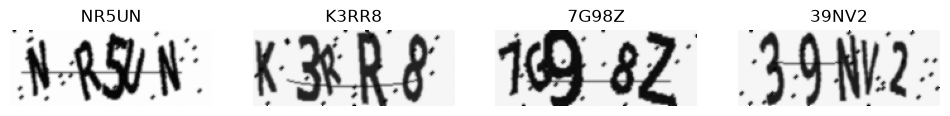

In [5]:
# Cell 4: checks
dataset = CaptchaDataset(10000)
loader = DataLoader(dataset, batch_size=64, num_workers=0)
xb, yb = next(iter(loader))
print(xb.shape, yb.shape)

fig, axes = plt.subplots(1, 4, figsize=(12, 2))
for i in range(4):
    axes[i].imshow(xb[i].squeeze(), cmap="gray")
    axes[i].set_title(decode(yb[i]))
    axes[i].axis("off")
plt.show()